# Modelos de regresión - Viajes en taxi de Nueva York (enero 2015)

Se entrenaron y compararon modelos de regresión sobre el dataset limpio `yellow_tripdata_2015-01_clean.csv` para predecir la duración del viaje (`trip_duration_min`) a partir de la hora de partida y las coordenadas de partida y llegada. Se excluye la distancia recorrida (`trip_distance`), pues el taxímetro solo la conoce al terminar el viaje y su uso supondría una fuga de información.

### Importar datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, ParameterGrid, train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler

PATH = "../data/yellow_tripdata_2015-01_clean.csv"
CHUNK = 2_000_000
cols = {1: "tpep_pickup_datetime", 5: "pickup_longitude", 6: "pickup_latitude",
        9: "dropoff_longitude", 10: "dropoff_latitude", 19: "trip_duration_min"}

partes = []
for chunk in pd.read_csv(PATH, header=None, skiprows=1, usecols=list(cols), chunksize=CHUNK):
    chunk.columns = list(cols.values())
    pickup = pd.to_datetime(chunk.pop("tpep_pickup_datetime"), format="%Y-%m-%d %H:%M:%S")
    chunk.insert(0, "pickup_hour", pickup.dt.hour + pickup.dt.minute / 60)
    partes.append(chunk.astype(np.float32))
df = pd.concat(partes, ignore_index=True)
del partes

features = ["pickup_hour", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
X = df[features].to_numpy()
y = df["trip_duration_min"].to_numpy(np.float64)
del df

print(f"Filas: {len(X):,}")
print(f"Variables: {features}")

Filas: 12,402,772
Variables: ['pickup_hour', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']


### Pipeline

Todos los modelos son regresiones lineales sin regularización que difieren en la transformación aplicada a las variables:
- **Lineal**: variables originales.
- **Dominio**: variables de dominio.
- **Dominio log**: variables de dominio, con objetivo `log(1 + duración)`.
- **Dominio + zonas**: variables de dominio y zonas de partida y llegada.
- **Dominio + zonas log**: variables de dominio y zonas, con objetivo `log(1 + duración)`.

Las coordenadas se proyectan en km (Transversa de Mercator centrada en Midtown) y se rotan 29° según la grilla de calles de Manhattan. Las variables de dominio son:
- Armónicos `sin(2πkh/24)` y `cos(2πkh/24)` de la hora de partida, con k = 1, ..., 8.
- Coordenadas proyectadas de partida y llegada, y su distancia a Midtown.
- Distancia en línea recta y Manhattan (L1) entre partida y llegada, e indicador de viajes con menos de 0.1 mi en línea recta.
- Orientación del viaje respecto de la grilla, `cos 2θ` (1 a lo largo de las avenidas, -1 en sentido transversal).
- Interacciones de la distancia en línea recta con los armónicos de la hora y con la distancia de partida y llegada a Midtown.

Las zonas se obtienen con k-means (`n_zonas` grupos) sobre los puntos de partida y llegada y se codifican con one-hot. Con objetivo logarítmico se agrega el logaritmo de la distancia en línea recta, y la predicción se devuelve a minutos con `exp(·) - 1` y un factor de corrección (smearing) estimado en entrenamiento.

Las transformaciones se ajustan con el conjunto de entrenamiento y sus variables se estandarizan. Por memoria, los mínimos cuadrados se resuelven acumulando las ecuaciones normales por bloques. Para cada modelo se selecciona la configuración con menor RMSE medio de validación.

In [2]:
PROYECCION = Transformer.from_crs("EPSG:4326", "+proj=tmerc +lat_0=40.754 +lon_0=-73.984 +ellps=WGS84 +units=km", always_xy=True)
ANGULO = np.deg2rad(29)

def proyectar(lon, lat):
    x, y = PROYECCION.transform(lon, lat)
    return x * np.sin(ANGULO) + y * np.cos(ANGULO), x * np.cos(ANGULO) - y * np.sin(ANGULO)

class Dominio(TransformerMixin, BaseEstimator):
    def __init__(self, armonicos=8, n_zonas=0, log_distancia=False):
        self.armonicos = armonicos
        self.n_zonas = n_zonas
        self.log_distancia = log_distancia

    def _puntos(self, X):
        return np.column_stack(proyectar(X[:, 1], X[:, 2])), np.column_stack(proyectar(X[:, 3], X[:, 4]))

    def fit(self, X, y=None):
        if self.n_zonas:
            self.kmeans_ = KMeans(self.n_zonas, n_init=3, random_state=67).fit(np.vstack(self._puntos(X)))
        return self

    def transform(self, X):
        p, q = self._puntos(X)
        dx, dy = q[:, 0] - p[:, 0], q[:, 1] - p[:, 1]
        d = np.hypot(dx, dy) / 1.609
        rp, rq = np.hypot(*p.T), np.hypot(*q.T)
        ang = 2 * np.pi * X[:, :1] * np.arange(1, self.armonicos + 1) / 24
        hora = np.hstack([np.sin(ang), np.cos(ang)])
        cols = [
            np.column_stack([d, (np.abs(dx) + np.abs(dy)) / 1.609, d < 0.1, np.cos(2 * np.arctan2(dy, dx)),
                             p, q, rp, rq, d * rp, d * rq]),
            hora, d[:, None] * hora,
        ]
        if self.log_distancia:
            cols.append(np.log(d + 0.05)[:, None])
        if self.n_zonas:
            zonas = np.eye(self.n_zonas)
            cols += [zonas[self.kmeans_.predict(p)], zonas[self.kmeans_.predict(q)]]
        return np.hstack(cols)

class MinimosCuadrados(RegressorMixin, BaseEstimator):
    def __init__(self, transformacion=None, objetivo="lineal", bloque=100_000):
        self.transformacion = transformacion
        self.objetivo = objetivo
        self.bloque = bloque

    def _bloques(self, X):
        return (slice(i, i + self.bloque) for i in range(0, len(X), self.bloque))

    def _variables(self, X):
        return self.transformacion_.transform(X.astype(np.float64))

    def _lineal(self, X):
        return np.concatenate([self.escala_.transform(self._variables(X[b])) @ self.coef_ + self.intercept_ for b in self._bloques(X)])

    def fit(self, X, y):
        transformacion = FunctionTransformer() if self.transformacion is None else self.transformacion
        self.transformacion_ = clone(transformacion).fit(X[:self.bloque].astype(np.float64))
        self.escala_ = StandardScaler()
        for b in self._bloques(X):
            self.escala_.partial_fit(self._variables(X[b]))
        t = np.log1p(y) if self.objetivo == "log" else y
        self.intercept_ = t.mean()
        ZtZ, Ztt = 0, 0
        for b in self._bloques(X):
            Z = self.escala_.transform(self._variables(X[b]))
            ZtZ, Ztt = ZtZ + Z.T @ Z, Ztt + Z.T @ (t[b] - self.intercept_)
        self.coef_ = np.linalg.lstsq(ZtZ, Ztt, rcond=None)[0]
        if self.objetivo == "log":
            self.correccion_ = np.exp(t - self._lineal(X)).mean()
        return self

    def predict(self, X):
        p = self._lineal(X)
        return np.exp(p) * self.correccion_ - 1 if self.objetivo == "log" else p

In [3]:
K = 5
N_CV = 2_000_000
METRICAS = ["MSE", "RMSE", "MAE", "R2"]

# def particionar(X, y):
#     X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67)
#     cv_idx = np.random.default_rng(67).choice(len(X_train), size=min(N_CV, len(X_train)), replace=False)
#     folds = [(cv_idx[tr], cv_idx[va]) for tr, va in KFold(n_splits=K, shuffle=True, random_state=67).split(cv_idx)]
#     print(f"Train + validación: {len(X_train):,}")
#     print(f"Test: {len(X_test):,}")
#     print(f"Muestra para validación cruzada: {len(cv_idx):,}")
#     print(f"Tamaño por fold: {len(folds[0][1]):,}")
#     return X_train, X_test, y_train, y_test, folds

N_MUESTRA = 100_000

def particionar(X, y):
    idx = np.random.default_rng(67).choice(len(X), size=N_MUESTRA, replace=False)
    X_train, X_test, y_train, y_test = train_test_split(X[idx], y[idx], test_size=0.2, random_state=67)
    folds = list(KFold(n_splits=K, shuffle=True, random_state=67).split(X_train))
    print(f"Muestra: {N_MUESTRA:,}")
    print(f"Train + validación: {len(X_train):,}")
    print(f"Test: {len(X_test):,}")
    print(f"Tamaño por fold: {len(folds[0][1]):,}")
    return X_train, X_test, y_train, y_test, folds

def metricas(y, y_pred):
    mse = mean_squared_error(y, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, y_pred), "R2": r2_score(y, y_pred)}

def config(params):
    return ", ".join(f"{k.split('__')[-1]}={v:g}" for k, v in sorted(params.items())) or "-"

def construir(modelo, params):
    return clone(modelo).set_params(**params)

def resumen(res):
    return res.groupby(["modelo", "config"], sort=False)[METRICAS].mean()

def entrenar(modelos, X, y, folds):
    entrenados, params_de, res = {}, {}, []
    for nombre, (modelo, grid) in modelos.items():
        for params in ParameterGrid(grid):
            cfg = config(params)
            params_de[nombre, cfg] = params
            for k, (tr, _) in enumerate(folds):
                m = construir(modelo, params).fit(X[tr], y[tr])
                entrenados[nombre, cfg, k] = m
                res.append({"modelo": nombre, "config": cfg, "fold": k + 1, **metricas(y[tr], m.predict(X[tr]))})
    return entrenados, params_de, pd.DataFrame(res)

def validar(entrenados, X, y, folds):
    res = []
    for (nombre, cfg, k), m in entrenados.items():
        va = folds[k][1]
        res.append({"modelo": nombre, "config": cfg, "fold": k + 1, **metricas(y[va], m.predict(X[va]))})
    return pd.DataFrame(res)

def seleccionar(train_cv, val_cv):
    mejor = dict(val_cv.groupby(["modelo", "config"], sort=False)["RMSE"].mean().groupby(level="modelo", sort=False).idxmin().tolist())
    mejor_df = pd.DataFrame(mejor.items(), columns=["modelo", "config"])
    comparacion = pd.concat({
        "train": train_cv.merge(mejor_df).groupby("modelo", sort=False)[METRICAS].mean(),
        "val": val_cv.merge(mejor_df).groupby("modelo", sort=False)[METRICAS].mean(),
    }, axis=1)
    comparacion.insert(0, "config", mejor_df.set_index("modelo")["config"])
    return mejor, comparacion

def entrenar_final(modelos, mejor, params_de, X, y):
    return {n: construir(modelos[n][0], params_de[n, mejor[n]]).fit(X, y) for n in modelos}

def coeficientes(finales):
    coefs = pd.DataFrame({n: m.coef_ for n, m in finales.items() if len(m.coef_) == len(features)}, index=features)
    coefs.loc["intercepto"] = [finales[n].intercept_ for n in coefs.columns]
    return coefs

def evaluar(finales, X, y):
    y_pred = {n: m.predict(X) for n, m in finales.items()}
    return y_pred, pd.DataFrame({n: metricas(y, p) for n, p in y_pred.items()}).T

In [4]:
labels = {
    "pickup_hour": "Hora de partida",
    "pickup_longitude": "Longitud partida", "pickup_latitude": "Latitud partida",
    "dropoff_longitude": "Longitud llegada", "dropoff_latitude": "Latitud llegada",
}

def rejilla(n, ancho, alto, cols=2):
    filas = -(-n // cols)
    fig, axes = plt.subplots(filas, min(n, cols), figsize=(ancho * min(n, cols), alto * filas), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:n]

def graficar_hiperparametros(modelos, val_cv):
    ajustables = [n for n, (_, grid) in modelos.items() if grid]
    fig, axes = rejilla(len(ajustables), 4.5, 3.4, cols=3)
    for ax, nombre in zip(axes, ajustables):
        grid = modelos[nombre][1]
        param, *otros = grid
        for fijos in ParameterGrid({k: grid[k] for k in otros}):
            cfgs = [config({param: v, **fijos}) for v in grid[param]]
            rmse = val_cv[val_cv["modelo"] == nombre].groupby("config")["RMSE"].mean().reindex(cfgs)
            ax.plot(grid[param], rmse, marker="o", label=config(fijos) if fijos else None)
        if max(grid[param]) / min(grid[param]) >= 10:
            ax.set_xscale("log")
        else:
            ax.set_xticks(grid[param])
        ax.set_xlabel(param.split("__")[-1])
        ax.set_ylabel("RMSE (min)")
        ax.set_title(nombre)
        if otros:
            ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    plt.suptitle("RMSE medio de validación según hiperparámetro")
    plt.tight_layout()
    plt.show()

def graficar_folds(val_cv, mejor):
    sel = val_cv.merge(pd.DataFrame(mejor.items(), columns=["modelo", "config"]))
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    w = 0.8 / len(mejor)
    folds_x = np.arange(1, K + 1)
    for ax, m in zip(axes, ["RMSE", "MAE", "R2"]):
        for i, nombre in enumerate(mejor):
            ax.bar(folds_x - 0.4 + w * (i + 0.5), sel.loc[sel["modelo"] == nombre, m], w, label=nombre)
        ax.set_xticks(folds_x)
        ax.set_xlabel("Fold")
        ax.set_title(m)
        ax.grid(alpha=0.3)
    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc="lower center", ncol=len(mejor), fontsize=8)
    plt.suptitle("Métricas de validación por fold")
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

def graficar_coeficientes(coefs):
    fig, ax = plt.subplots(figsize=(6, 3.6))
    pos = np.arange(len(features))
    h = 0.8 / len(coefs.columns)
    for i, nombre in enumerate(coefs.columns):
        ax.barh(pos - 0.4 + h * (i + 0.5), coefs.loc[features, nombre], h, label=nombre)
    ax.set_yticks(pos)
    ax.set_yticklabels([labels[f] for f in features])
    ax.axvline(0, color="black", lw=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("Coeficiente (min por desviación estándar)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.title("Coeficientes de los modelos")
    plt.tight_layout()
    plt.show()

def graficar_test(y, y_pred, n=500_000):
    sample = np.random.default_rng(67).choice(len(y), size=min(n, len(y)), replace=False)
    y_s = y[sample]
    y_max = np.quantile(y_s, 0.99)
    res_s = {nombre: y_s - p[sample] for nombre, p in y_pred.items()}
    res_lim = max(np.quantile(np.abs(r), 0.99) for r in res_s.values())

    fig, axes = rejilla(len(y_pred), 4.5, 4.5)
    for ax, nombre in zip(axes, y_pred):
        ax.scatter(y_s, y_pred[nombre][sample], s=8, alpha=0.35, rasterized=True)
        ax.plot([0, y_max], [0, y_max], color="tab:red", lw=2, ls="--")
        ax.set_xlim(0, y_max)
        ax.set_ylim(0, y_max)
        ax.set_xlabel("Duración real (min)")
        ax.set_ylabel("Duración predicha (min)")
        ax.set_title(nombre)
        ax.grid(alpha=0.3)
    plt.suptitle("Valores reales vs predichos")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 3.6))
    bins = np.linspace(-res_lim, res_lim, 61)
    for nombre, r in res_s.items():
        ax.hist(r.clip(-res_lim, res_lim), bins=bins, histtype="step", lw=1.5, label=nombre)
    ax.set_xlabel("Residuo (min)")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.title("Distribución de los residuos")
    plt.tight_layout()
    plt.show()

    fig, axes = rejilla(len(y_pred), 4.5, 3.6)
    for ax, nombre in zip(axes, y_pred):
        p = y_pred[nombre][sample]
        ax.scatter(p, res_s[nombre], s=8, alpha=0.35, rasterized=True)
        ax.axhline(0, color="tab:red", lw=2, ls="--")
        ax.set_xlim(0, np.quantile(p, 0.99))
        ax.set_ylim(-res_lim, res_lim)
        ax.set_xlabel("Duración predicha (min)")
        ax.set_ylabel("Residuo (min)")
        ax.set_title(nombre)
        ax.grid(alpha=0.3)
    plt.suptitle("Residuos vs predicción")
    plt.tight_layout()
    plt.show()

### Partición de datos

Se reserva el 20% de los datos como conjunto de test. Del 80% restante se toma una muestra aleatoria de 2 M de viajes que se divide en K = 5 folds para validación cruzada (entrenamiento y validación).

In [5]:
modelos = {
    "Lineal": (MinimosCuadrados(), {}),
    "Dominio": (MinimosCuadrados(Dominio()), {}),
    "Dominio log": (MinimosCuadrados(Dominio(log_distancia=True), objetivo="log"), {}),
    "Dominio + zonas": (MinimosCuadrados(Dominio()), {"transformacion__n_zonas": [20, 50, 100]}),
    "Dominio + zonas log": (MinimosCuadrados(Dominio(log_distancia=True), objetivo="log"), {"transformacion__n_zonas": [20, 50, 100]}),
}

X_train, X_test, y_train, y_test, folds = particionar(X, y)
del X, y

Muestra: 100,000
Train + validación: 80,000
Test: 20,000
Tamaño por fold: 16,000


### Entrenamiento

Para cada modelo y configuración de hiperparámetros se entrena un modelo por fold con los K - 1 folds restantes.

In [6]:
entrenados, params_de, train_cv = entrenar(modelos, X_train, y_train, folds)
resumen(train_cv).round(4)

MSE    RMSE     MAE      R2
modelo              config                                      
Lineal              -            69.6075  8.3429  5.8924  0.1994
Dominio             -            30.3446  5.5080  3.3692  0.6511
Dominio log         -            30.1383  5.4892  3.2872  0.6534
Dominio + zonas     n_zonas=20   29.2099  5.4040  3.2859  0.6641
                    n_zonas=50   28.8243  5.3682  3.2593  0.6686
                    n_zonas=100  28.5145  5.3393  3.2401  0.6721
Dominio + zonas log n_zonas=20   29.5691  5.4370  3.2406  0.6600
                    n_zonas=50   29.3494  5.4168  3.2177  0.6625
                    n_zonas=100  29.1799  5.4011  3.2016  0.6645

### Validación

Cada modelo se evalúa sobre el fold que no se usó en su entrenamiento.

In [7]:
val_cv = validar(entrenados, X_train, y_train, folds)
resumen(val_cv).round(4)

MSE    RMSE     MAE      R2
modelo              config                                      
Lineal              -            69.6344  8.3418  5.8929  0.1989
Dominio             -            30.4368  5.5083  3.3724  0.6509
Dominio log         -            30.2166  5.4879  3.2904  0.6535
Dominio + zonas     n_zonas=20   29.4113  5.4130  3.2925  0.6629
                    n_zonas=50   29.1382  5.3874  3.2682  0.6660
                    n_zonas=100  29.0570  5.3802  3.2610  0.6669
Dominio + zonas log n_zonas=20   29.7072  5.4396  3.2458  0.6595
                    n_zonas=50   29.5595  5.4257  3.2262  0.6612
                    n_zonas=100  29.8235  5.4485  3.2256  0.6584

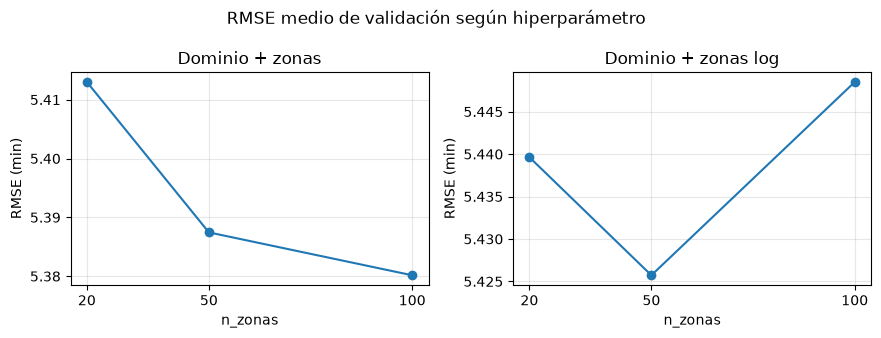

In [8]:
graficar_hiperparametros(modelos, val_cv)

In [9]:
mejor, comparacion = seleccionar(train_cv, val_cv)
comparacion.round(4)

config    train                              val  \
                                      MSE    RMSE     MAE      R2      MSE   
modelo                                                                       
Lineal                         -  69.6075  8.3429  5.8924  0.1994  69.6344   
Dominio                        -  30.3446  5.5080  3.3692  0.6511  30.4368   
Dominio log                    -  30.1383  5.4892  3.2872  0.6534  30.2166   
Dominio + zonas      n_zonas=100  28.5145  5.3393  3.2401  0.6721  29.0570   
Dominio + zonas log   n_zonas=50  29.3494  5.4168  3.2177  0.6625  29.5595   

                                             
                       RMSE     MAE      R2  
modelo                                       
Lineal               8.3418  5.8929  0.1989  
Dominio              5.5083  3.3724  0.6509  
Dominio log          5.4879  3.2904  0.6535  
Dominio + zonas      5.3802  3.2610  0.6669  
Dominio + zonas log  5.4257  3.2262  0.6612

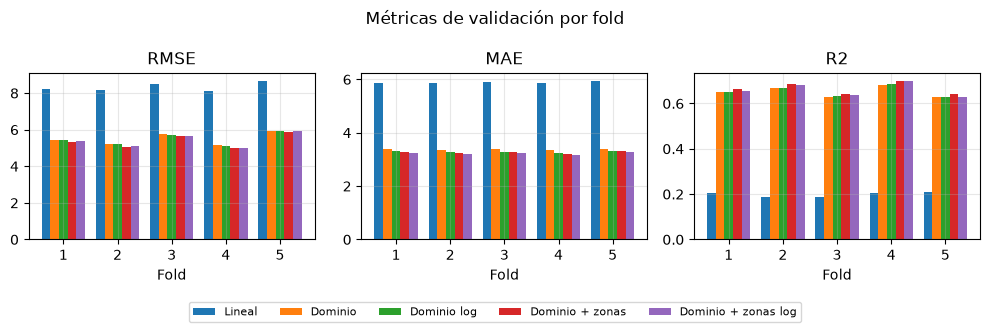

In [10]:
graficar_folds(val_cv, mejor)

### Modelo final

Cada modelo se reentrena con su mejor configuración sobre todo el conjunto de entrenamiento y validación.

In [11]:
finales = entrenar_final(modelos, mejor, params_de, X_train, y_train)
print("Número de variables por modelo:")
for nombre, m in finales.items():
    print(f"  {nombre}: {len(m.coef_)}")
coefs = coeficientes(finales)
coefs.round(4)

Número de variables por modelo:
  Lineal: 5
  Dominio: 44
  Dominio log: 45
  Dominio + zonas: 244
  Dominio + zonas log: 145


,Lineal
pickup_hour,0.1333
pickup_longitude,2.5898
pickup_latitude,-1.2249
dropoff_longitude,1.9050
dropoff_latitude,-1.5211
intercepto,12.3249


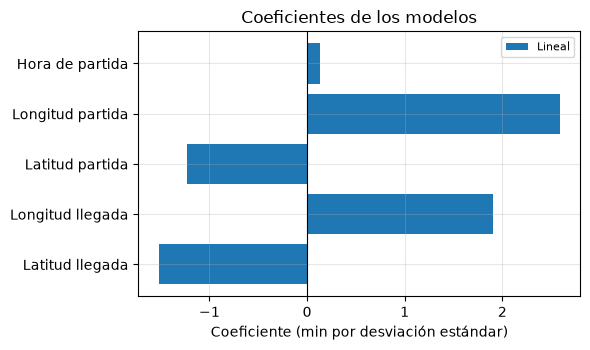

In [12]:
graficar_coeficientes(coefs)

### Evaluación en test

Los modelos finales se evalúan sobre el conjunto de test. Las gráficas se realizaron sobre una muestra aleatoria de 500 mil viajes del conjunto de test, recortando los ejes al percentil 99 únicamente para mejorar la visualización.

In [13]:
y_pred, test = evaluar(finales, X_test, y_test)
test.round(4)

,MSE,RMSE,MAE,R2
Lineal,67.7588,8.2316,5.9128,0.1983
Dominio,29.0313,5.3881,3.3855,0.6565
Dominio log,28.7877,5.3654,3.3154,0.6594
Dominio + zonas,27.8040,5.2730,3.2670,0.6710
Dominio + zonas log,28.5319,5.3415,3.2510,0.6624


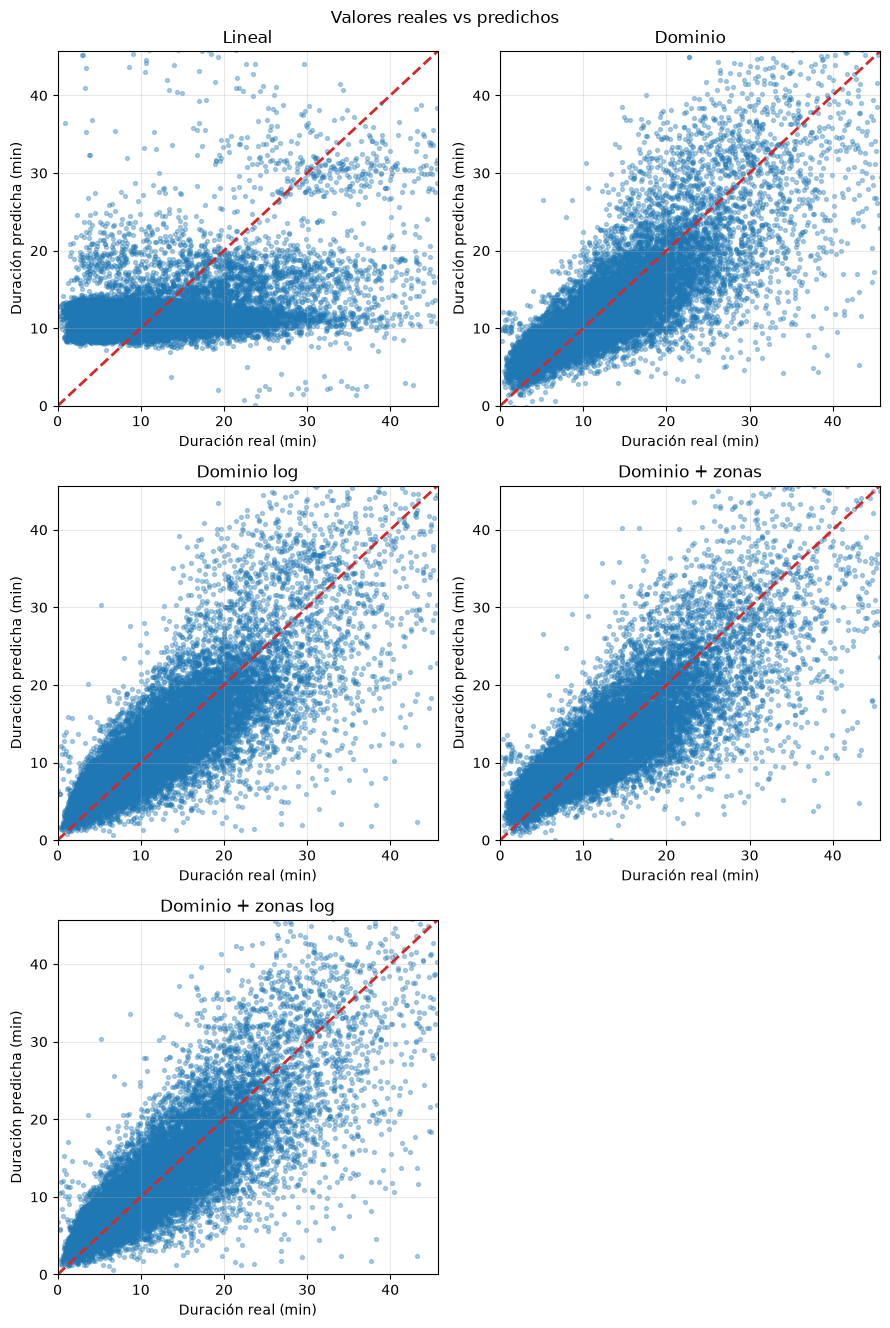

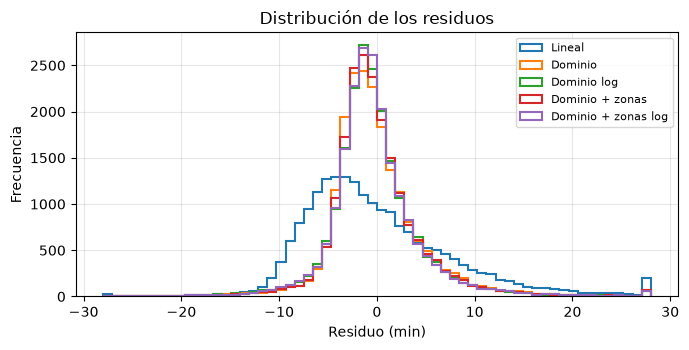

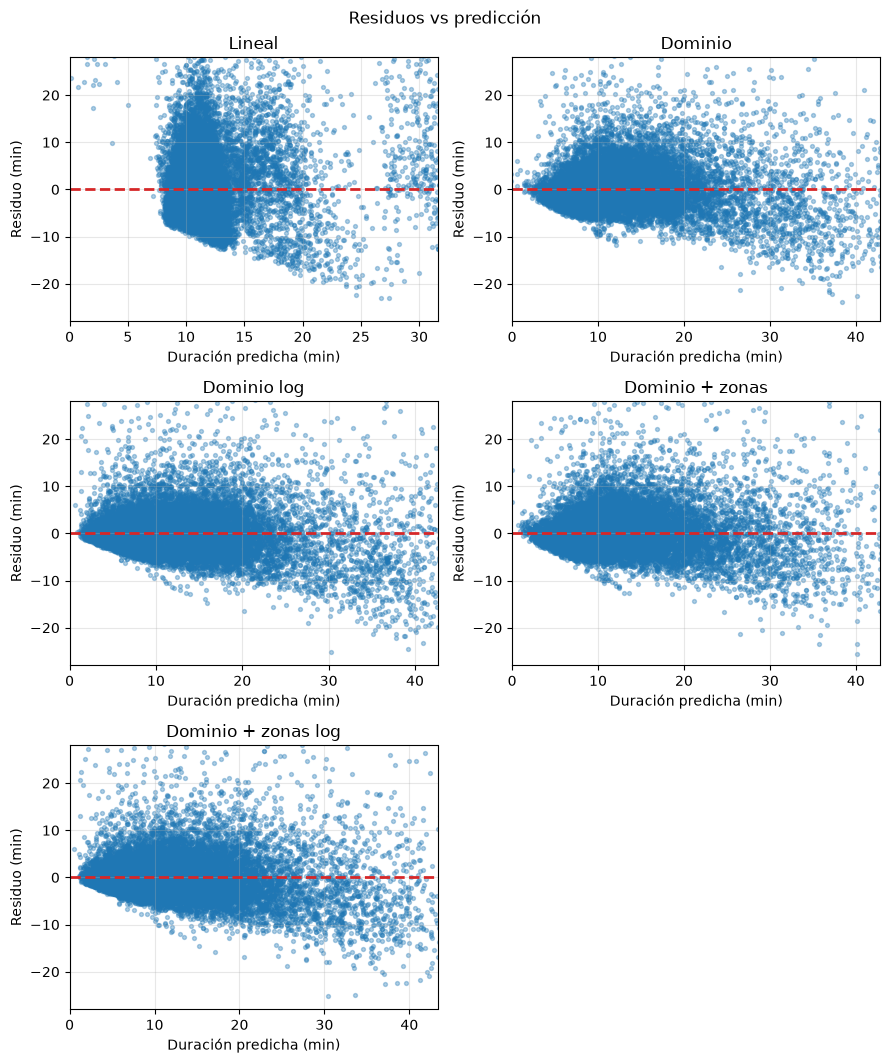

In [14]:
graficar_test(y_test, y_pred)